# Pluggable output writers

ECGProcess writes processed data through a registry of *writers*. A writer
is selected with the `writer` argument of `ECGTable.write_ecg`, either by
its registry key (e.g. `'npy'`, `'figure'`) or by passing a custom writer
object. The available keys live in `ecgprocess.writer.WRITERS`.

In this recipe we walk through each built-in writer - the tabular
`table`, the bundled `npz`, the per-array `npy`, the `tensorflow`
tfrecord writer, and the figure-based `figure` and `pixel` writers - and
then show how to plug in your own writer, first as a bare function and
then as a registered `BaseWriter` subclass.

First we import the relevant functions and classes and load some example
data.

In [1]:
import io
import os
import importlib.util
import tempfile
import matplotlib
# a non-interactive backend for headless figure rendering
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from ecgprocess.tabular import ECGTable
from ecgprocess.writer import (
    WRITERS,
    BaseWriter,
    FigureWriter,
    PixelWriter,
    register_writer,
)
from ecgprocess.plot_ecgs import ECGStyle
from ecgprocess.process_dicom import ECGDICOMReader
from ecgprocess.example_data.examples import (
    parsed_config,
    list_dicom_paths,
)
# #### example DICOM files and their parsed config
dicom_path_list = [
    list_dicom_paths()['example_dicom_1'],
    list_dicom_paths()['example_dicom_2'],
]
parser_dicom = parsed_config()['parsed_dicom1']
# the registry keys accepted as `writer=` values
print(f'Available pre-defined writers: {sorted(WRITERS)}.')

Available pre-defined writers: ['figure', 'npy', 'npz', 'pixel', 'table', 'tensorflow'].


## Tab-delimited tables (`writer='table'`)

The `table` writer is the default. It writes each extracted source to a
gzip-compressed, tab-delimited file - `metadata.tsv.gz`,
`waveforms.tsv.gz`, and `medianbeats.tsv.gz` - in long format, so records
of differing length need no padding. It is covered in depth in the
*Scaled processing of ECG data* recipe and shown here for completeness.

In [2]:
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    ecgtable = ECGTable(reader, path_list=dicom_path_list)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False, writer='table')
    print('Directory content:')
    for file_name in sorted(os.listdir(getattr(res, 'target_path'))):
        print('   - {}'.format(file_name))

Directory content:
   - medianbeats.tsv.gz
   - metadata.tsv.gz
   - waveforms.tsv.gz


## Bundled NumPy archive (`writer='npz'`)

The `npz` writer bundles every extracted source into a single NumPy
`.npz` archive (`ecg_data.npz`), with the non-numeric metadata columns
dropped and their names written to a `header_metadata.txt` sidecar.
Because the sources are stacked into arrays, we fix a common signal
length first.

In [3]:
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    # a common length lets the per-record signals stack into one array
    ecgtable = ECGTable(reader, path_list=dicom_path_list,
                        signal_length_w=5000, signal_length_m=600)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False, writer='npz')
    target = getattr(res, 'target_path')
    print('Directory content:')
    for file_name in sorted(os.listdir(target)):
        print('   - {}'.format(file_name))
    with np.load(os.path.join(target, 'ecg_data.npz')) as data:
        median = data['MedianBeats']
# (n_records, n_leads, n_samples)
median.shape

The following non-numerical columns were dropped when converting data to numpy arrays: {'resolution unit (waveforms)', 'resolution unit (medianbeats)', 'Manufacturer', 'key', 'Model name', 'sampling frequency unit', 'unique identifier', 'filename', 'Softwave version'}.


Directory content:
   - ecg_data.npz
   - header_metadata.txt


(2, 12, 600)

## Per-array NumPy files (`writer='npy'`)

The `npy` writer stores each data source in its own `.npy` file -
`metadata.npy`, `waveforms.npy`, and `medianbeats.npy` - casting the
signals to a configurable dtype (`float32` by default). This differs from
the `npz` writer, which bundles every source into a single `.npz`
archive. Because NumPy holds only numerical data, non-numeric metadata
columns are dropped and their column names are written to a
`header_metadata.txt` sidecar.

In [4]:
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    # the lead-specific signals differ in length, so we fix a common
    # length (pad/truncate) before writing to arrays
    ecgtable = ECGTable(reader, path_list=dicom_path_list,
                        signal_length_w=5000, signal_length_m=600,)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False, writer='npy')
    target = getattr(res, 'target_path')
    print('Directory content:')
    for file_name in sorted(os.listdir(target)):
        print('   - {}'.format(file_name))
    # read the median beats back in before the temp dir disappears
    median = np.load(os.path.join(target, 'medianbeats.npy'),
                     allow_pickle=False)
# (n_records, n_leads, n_samples)
median.shape

The following non-numerical columns were dropped when converting data to numpy arrays: {'resolution unit (waveforms)', 'resolution unit (medianbeats)', 'Manufacturer', 'key', 'Model name', 'sampling frequency unit', 'unique identifier', 'filename', 'Softwave version'}.


Directory content:
   - header_metadata.txt
   - medianbeats.npy
   - metadata.npy
   - waveforms.npy


(2, 12, 600)

## TensorFlow records (`writer='tensorflow'`)

The `tensorflow` writer serialises the stacked arrays into binary
`tfrecord` files (`ecg_data.tfrecord`), the native input format for
`tf.data` pipelines. TensorFlow is an optional dependency
(`pip install ecgprocess[tensorflow]`), so we only run this writer when
it is installed.

In [5]:
if importlib.util.find_spec('tensorflow') is not None:
    with tempfile.TemporaryDirectory() as temp_dir:
        os.chdir(temp_dir)
        reader = ECGDICOMReader()
        ecgtable = ECGTable(reader, path_list=dicom_path_list,
                            signal_length_w=5000, signal_length_m=600)
        res = ecgtable(verbose=False).write_ecg(
            parsed_config=parser_dicom, write_failed=False,
            writer='tensorflow')
        print('Directory content:')
        for file_name in sorted(os.listdir(getattr(res, 'target_path'))):
            print('   - {}'.format(file_name))
else:
    print('tensorflow writer skipped: optional dependency not installed')

I0000 00:00:1784325311.995303   22237 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
The following non-numerical columns were dropped when converting data to numpy arrays: {'resolution unit (waveforms)', 'resolution unit (medianbeats)', 'Manufacturer', 'key', 'Model name', 'sampling frequency unit', 'unique identifier', 'filename', 'Softwave version'}.


Directory content:
   - ecg_data.tfrecord
   - header_metadata.txt


## Rendered figures (`writer='figure'`)

The `figure` writer renders one ECG image per record through an `ECGDrawing` and saves it as `<UID>.<image_format>` (PNG by default).
It renders exactly one signal source, so we disable median-beat extraction with `extract_median=False`; extracting both waveforms and
median beats raises an error. To render median beats instead, build the writer with `FigureWriter(source='median', tile_x=False)` and extract
only that source with `extract_wave=False`. 

The DICOM example signals are in microvolts, so we pass an `ECGStyle` scaled to a clinical print
(`y_lim=(-2000, 2000)`, `mm_per_mv=10/1000`) via `kwargs_call`; anything `ECGDrawing.__call__` accepts can be forwarded there.

In [6]:
# clinical scaling for the microvolt DICOM signals
style = ECGStyle(y_lim=(-2000, 2000), mm_per_mv=10 / 1000)
fig_writer = FigureWriter(kwargs_call={
    'style': style,
    'sampling_rate': 500,
    'show_lead_labels': True,
    'cal_pulse': 'square',
})
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    # the figure writer renders exactly one source
    ecgtable = ECGTable(reader, path_list=dicom_path_list,
                        extract_median=False)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False, writer=fig_writer)
    target = getattr(res, 'target_path')
    print('Directory content:')
    for file_name in sorted(os.listdir(target)):
        print('   - {}'.format(file_name))
    # read one rendered image into memory before the temp dir disappears
    png_name = sorted(f for f in os.listdir(target) if f.endswith('.png'))[0]
    with open(os.path.join(target, png_name), 'rb') as fh:
        png_bytes = fh.read()
Image(data=png_bytes)

Directory content:
   - 1.3.6.1.4.1.40744.65.221835449869280278116555339248567804126.png
   - 2.25.269796857626990821315969488216511468638.png


## Stacked pixel tensors (`writer='pixel'`)

The `pixel` writer renders each record exactly like `figure`, but instead of an image file it rasterises the figures and stacks them into a single
`(n_records, height, width, channels)` NHWC tensor saved as `figures.npy`, with a row-aligned `metadata.tsv`. 
Like `figure` it renders a single source (`extract_median=False` here); `channels='gray'`
keeps a single channel axis, and the figure `style` defined above is reused for scaling.

We also pass an `annotate` spec so the ECG calibration (`25 mm/s`,`10 mm/mV`) is drawn onto each figure *before* it is rasterised, becoming
part of the tensor. 

Finally we read `figures.npy` back from disk and plot the first record to confirm the round-trip.

Directory content:
   - figures.npy
   - metadata.tsv
tensor shape (n_records, height, width, channels): (2, 6000, 12000, 1)



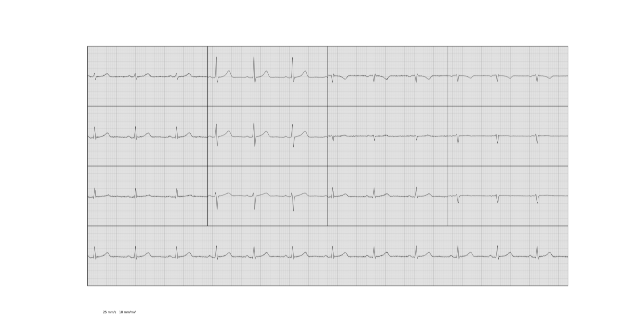

In [7]:
# annotate each figure with the ECG calibration before rasterising, so
# the unit label becomes part of the stored pixel tensor
pixel_writer = PixelWriter(
    channels='gray',
    kwargs_call={'style': style, 'sampling_rate': 500},
    annotate=[{'text': '25 mm/s   10 mm/mV', 'xy': (0.15, 0.02)}],
)
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    ecgtable = ECGTable(reader, path_list=dicom_path_list,
                        extract_median=False)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False, writer=pixel_writer)
    target = getattr(res, 'target_path')
    print('Directory content:')
    for file_name in sorted(os.listdir(target)):
        print('   - {}'.format(file_name))
    # read the stacked tensor back from disk
    tensor = np.load(os.path.join(target, 'figures.npy'), allow_pickle=False)
print('tensor shape (n_records, height, width, channels):', tensor.shape)
print('')

# #### plot the first record back from the tensor
fig, ax = plt.subplots(figsize=(8, 6))
# grayscale keeps a channel axis; drop it for imshow
ax.imshow(tensor[0, :, :, 0], cmap='gray')
# ax.set_title('pixel tensor - record 0 (calibration annotation baked in)')
ax.axis('off')
buf = io.BytesIO()
fig.savefig(buf, format='png', dpi=100, bbox_inches='tight')
plt.close(fig)
Image(data=buf.getvalue())

## Bringing your own writer

The `writer` argument also accepts user-supplied writers, so new output
formats need no changes to library code. The simplest form is a bare
callable matching the `BaseWriter.write` signature
`(meta_list, wave_list, median_list, ctx)`, where the three lists hold
the extracted metadata, waveform, and median-beat records for the chunk.

The final argument, `ctx`, is a `WriteContext` (from
`ecgprocess.writer`) that carries everything a writer needs from
`ECGTable`:

- `ctx.target` - the output directory to write into;
- `ctx.key_list` - the per-record unique identifiers (UIDs), aligned
  element-by-element with the three record lists;
- `ctx.e_meta`, `ctx.e_wave`, `ctx.e_median` - which sources were
  extracted;
- `ctx.chunk_num` - the current chunk number (`None` when all records
  are written in one go), appended to the standard filenames;
- `ctx.skip_data` and `ctx.failed_records` - bookkeeping for records a
  writer chooses to skip rather than fail on.

Here a small function writes a one-line-per-record summary of how many
leads each waveform carries.

In [8]:
def summary_writer(meta_list, wave_list, median_list, ctx):
    """Write a per-record lead-count summary to `summary.txt`."""
    lines = []
    for uid, wave in zip(ctx.key_list, wave_list, strict=True):
        n_leads = sum(arr is not None for arr in wave.values())
        lines.append('{}\t{} leads'.format(uid, n_leads))
    with open(os.path.join(ctx.target, 'summary.txt'), 'w') as fh:
        fh.write('\n'.join(lines) + '\n')

with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    ecgtable = ECGTable(reader, path_list=dicom_path_list)
    # pass the function directly as the writer
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False,
        writer=summary_writer)
    with open(os.path.join(getattr(res, 'target_path'), 'summary.txt')) as fh:
        print(fh.read())

2.25.269796857626990821315969488216511468638	12 leads
1.3.6.1.4.1.40744.65.221835449869280278116555339248567804126	12 leads



For a reusable, named format, subclass `BaseWriter` and register it
with the `register_writer` decorator. Registration adds the class to
`WRITERS` under a key, so it can then be selected with `writer='<key>'`
exactly like a built-in writer.

Rather than hard-code an output name, the writer below reuses
`BaseWriter.file_names`, which returns the standard per-chunk filenames
(with the writer's `FILE_EXT` extension and any chunk suffix). We take
the first of these, the metadata filename (`metadata.tsv`), because the
lead count is one tabular row of metadata per record. Writing it under
the standard metadata name means the output follows the same naming and
chunking scheme as the built-in writers.

In [9]:
@register_writer('lead_count')
class LeadCountWriter(BaseWriter):
    """Write the per-record non-empty lead count as a `.tsv` table."""
    # the extension appended to the standard filenames
    FILE_EXT = '.tsv'
    def write(self, meta_list, wave_list, median_list, ctx):
        """Write one `metadata.tsv` row per record."""
        # the standard metadata filename for this chunk, e.g.
        # `metadata.tsv` (or `metadata_0.tsv` when chunked)
        meta_file, *_ = self.file_names(chunk_num=ctx.chunk_num)
        rows = ['uid\tn_leads']
        for uid, wave in zip(ctx.key_list, wave_list, strict=True):
            n_leads = sum(arr is not None for arr in wave.values())
            rows.append('{}\t{}'.format(uid, n_leads))
        with open(os.path.join(ctx.target, meta_file), 'w') as fh:
            fh.write('\n'.join(rows) + '\n')

# Now using lead_count writer and reading this back in using with.
with tempfile.TemporaryDirectory() as temp_dir:
    os.chdir(temp_dir)
    reader = ECGDICOMReader()
    ecgtable = ECGTable(reader, path_list=dicom_path_list)
    res = ecgtable(verbose=False).write_ecg(
        parsed_config=parser_dicom, write_failed=False,
        writer='lead_count')
    with open(os.path.join(getattr(res, 'target_path'),
                           'metadata.tsv')) as fh:
        print(fh.read())

uid	n_leads
2.25.269796857626990821315969488216511468638	12
1.3.6.1.4.1.40744.65.221835449869280278116555339248567804126	12

